<a href="https://colab.research.google.com/github/tuhin-hash/City-But_in_reality/blob/main/ANN_SDP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print('Tensorflow Version', tf.__version__)

Tensorflow Version 2.21.0


In [2]:
# Load the MNIST dataset
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print('Training Images', x_train.shape)
print('Training Labels', y_train.shape)
print('Testing Images', x_test.shape)
print('Testing Labels', y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images (60000, 28, 28)
Training Labels (60000,)
Testing Images (10000, 28, 28)
Testing Labels (10000,)


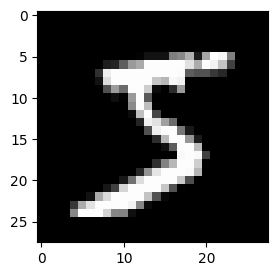

In [8]:
# Display a handwritten image
plt.figure(figsize=(10,3))
plt.imshow(x_train[0], cmap='gray')
plt.show()

In [9]:
# Normalize the pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print('Minimum pixel value', x_train.min())
print('Maximum pixel value', x_train.max())

Minimum pixel value 0.0
Maximum pixel value 1.0


In [10]:
# Build the ANN model
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])



In [20]:
# Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9967 - loss: 0.0100 - val_accuracy: 0.9919 - val_loss: 0.0235
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9984 - loss: 0.0065 - val_accuracy: 0.9911 - val_loss: 0.0264
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9981 - loss: 0.0066 - val_accuracy: 0.9887 - val_loss: 0.0368
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9981 - loss: 0.0059 - val_accuracy: 0.9913 - val_loss: 0.0287
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9987 - loss: 0.0043 - val_accuracy: 0.9875 - val_loss: 0.0411


In [23]:
# Evaluate the model
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test Accuracy', test_acc*100,'%')
print('Test Loss', test_loss*100,'%')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9759 - loss: 0.1098
Test Accuracy 97.58999943733215 %
Test Loss 10.976509749889374 %


In [24]:
# Predict  a handwritten digit
predictions = model.predict(x_test)
for i in range(5):
  predicted_digit = np.argmax(predictions[i])
  actual_digit = y_test[i]

  print(f"Predicted: {predicted_digit}, Actual: {actual_digit}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted: 7, Actual: 7
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 4, Actual: 4


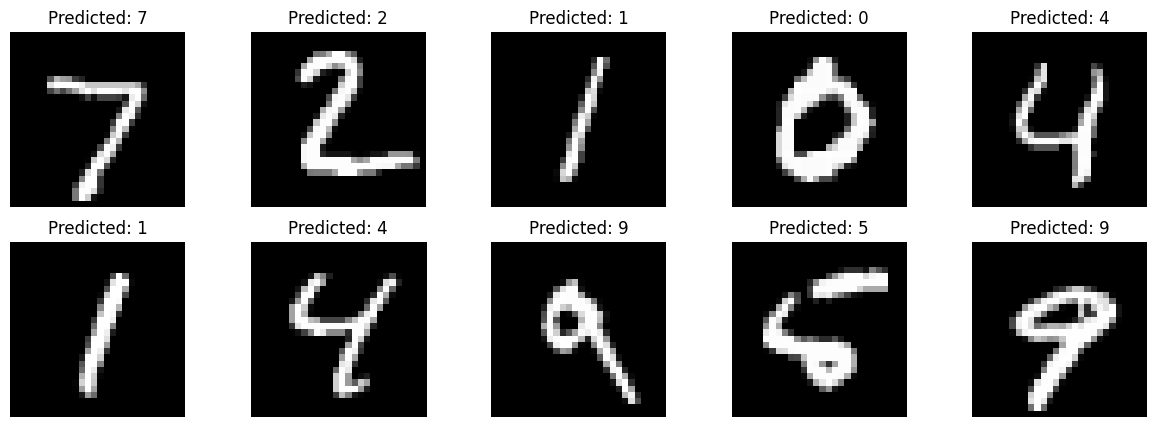

In [37]:
# Display Predictions
plt.figure(figsize=(15,5))
for i in range(10):
  plt.subplot(2,5,i+1)
  predictions = model.predict(x_test[i:i+1], verbose = 0)
  predicted_digit = np.argmax(predictions[0])
  plt.imshow(x_test[i], cmap='gray')
  plt.title(f"Predicted: {predicted_digit}")
  plt.axis('off')
plt.show()